In [124]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay)

In [125]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/employee_attrition_20000.csv")

In [126]:
df.head()

,EmployeeID,Age,Department,JobRole,MonthlyIncome,YearsAtCompany,YearsInCurrentRole,JobSatisfaction,WorkLifeBalance,OverTime,DistanceFromHome,TrainingTimesLastYear,YearsSinceLastPromotion,Attrition
0,EMP000001,54,Finance,Manager,85898,10,10,3,2,No,3,4,2,No
1,EMP000002,25,IT,Developer,57738,7,6,2,3,No,27,1,7,No
2,EMP000003,19,Research & Development,Research Director,30875,1,0,4,1,No,8,2,1,No
3,EMP000004,45,Human Resources,HR Manager,66559,18,9,2,2,Yes,27,3,12,No
4,EMP000005,33,Sales,Sales Representative,56119,15,0,4,2,Yes,2,5,6,No


In [127]:
df.shape

(20000, 14)

In [128]:
df.columns

Index(['EmployeeID', 'Age', 'Department', 'JobRole', 'MonthlyIncome',
       'YearsAtCompany', 'YearsInCurrentRole', 'JobSatisfaction',
       'WorkLifeBalance', 'OverTime', 'DistanceFromHome',
       'TrainingTimesLastYear', 'YearsSinceLastPromotion', 'Attrition'],
      dtype='object')

In [129]:
df.duplicated().sum()

np.int64(0)

In [130]:
df.describe()

,Age,MonthlyIncome,YearsAtCompany,YearsInCurrentRole,JobSatisfaction,WorkLifeBalance,DistanceFromHome,TrainingTimesLastYear,YearsSinceLastPromotion
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.0000,20000.000000
mean,39.059850,64518.106150,11.220450,4.467500,2.498500,2.496550,25.36725,3.0088,4.596800
std,12.423244,17645.231119,8.125556,4.087442,1.118597,1.121807,14.38257,2.0048,4.265271
min,18.000000,18000.000000,0.000000,0.000000,1.000000,1.000000,1.00000,0.0000,0.000000
25%,28.000000,52235.500000,4.000000,1.000000,1.000000,1.000000,13.00000,1.0000,1.000000
50%,39.000000,64428.500000,10.000000,3.000000,2.000000,3.000000,25.00000,3.0000,3.000000
75%,50.000000,76905.250000,17.000000,7.000000,3.000000,4.000000,38.00000,5.0000,7.000000
max,60.000000,129849.000000,30.000000,14.000000,4.000000,4.000000,50.00000,6.0000,15.000000


In [131]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   EmployeeID               20000 non-null  object
 1   Age                      20000 non-null  int64 
 2   Department               20000 non-null  object
 3   JobRole                  20000 non-null  object
 4   MonthlyIncome            20000 non-null  int64 
 5   YearsAtCompany           20000 non-null  int64 
 6   YearsInCurrentRole       20000 non-null  int64 
 7   JobSatisfaction          20000 non-null  int64 
 8   WorkLifeBalance          20000 non-null  int64 
 9   OverTime                 20000 non-null  object
 10  DistanceFromHome         20000 non-null  int64 
 11  TrainingTimesLastYear    20000 non-null  int64 
 12  YearsSinceLastPromotion  20000 non-null  int64 
 13  Attrition                20000 non-null  object
dtypes: int64(9), object(5)
memory usage: 2

In [132]:
df.duplicated().sum()

np.int64(0)

In [133]:
df.isnull().sum()

EmployeeID                 0
Age                        0
Department                 0
JobRole                    0
MonthlyIncome              0
YearsAtCompany             0
YearsInCurrentRole         0
JobSatisfaction            0
WorkLifeBalance            0
OverTime                   0
DistanceFromHome           0
TrainingTimesLastYear      0
YearsSinceLastPromotion    0
Attrition                  0
dtype: int64

In [134]:
df=df.drop(columns="EmployeeID")

In [135]:
X=df.drop(columns="Attrition")
y=df["Attrition"].map({
    "No":0,
    "Yes":1
})

In [136]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20000, 12)
y shape: (20000,)


In [137]:
numerical_cols=X.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_cols=X.select_dtypes(include=["object"]).columns.tolist()

In [138]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(16000, 12)
(4000, 12)
(16000,)
(4000,)


In [139]:
numerical_transformer=Pipeline(steps=[
    ("impter",SimpleImputer(strategy="median")),
    ("scler",StandardScaler())
])

categorical_transformer=Pipeline(steps=[
    ("impter",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

In [140]:
preprocessing=ColumnTransformer(transformers=[
    ("num",numerical_transformer,numerical_cols),
    ("cat",categorical_transformer,categorical_cols)
])

In [141]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1)

In [142]:
model = Pipeline(steps=[
    ("preprocessing", preprocessing),
    ("classifier", rf_model)])

In [143]:
model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Age','Department','JobRole',...,'DistanceFromHome', 'TrainingTimesLastYear','YearsSinceLastPromotion']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By speci

In [144]:
y_pred=model.predict(X_test)

In [145]:
from sklearn.metrics import accuracy_score
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy_score:",accuracy)

Accuracy_score: 0.74


In [146]:
from sklearn.metrics import precision_score
precision=precision_score(y_test,y_pred)
print("Precision_score:",precision)

Precision_score: 0.20302375809935205


In [147]:
from sklearn.metrics import recall_score
recal=recall_score(y_test,y_pred)
print("Recal_Score:",recal)

Recal_Score: 0.3836734693877551


In [148]:
from sklearn.metrics import f1_score
f1=f1_score(y_test,y_pred)
print("F1_score:",f1)

F1_score: 0.2655367231638418


In [149]:
from sklearn.metrics import roc_auc_score
roc=roc_auc_score(y_test,y_pred)
print("Roc_auc_score:",roc)

Roc_auc_score: 0.5867085295656723


In [150]:
print(classification_report(y_test,y_pred,target_names=["No Attrition", "Attrition"]))

              precision    recall  f1-score   support

No Attrition       0.90      0.79      0.84      3510
   Attrition       0.20      0.38      0.27       490

    accuracy                           0.74      4000
   macro avg       0.55      0.59      0.55      4000
weighted avg       0.82      0.74      0.77      4000



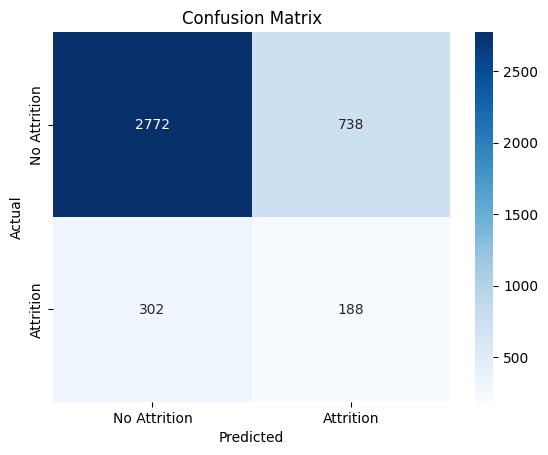

In [151]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Attrition", "Attrition"],
    yticklabels=["No Attrition", "Attrition"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()